# Pump Telemetry Presentation Workbook

## Helper Functions:

In [64]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.signal import savgol_filter
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
hidden_dir = project_root / 'Hidden'
if str(hidden_dir) not in sys.path:
    sys.path.insert(0, str(hidden_dir))

import presentation_emulator as _presentation_emulator
_presentation_emulator = importlib.reload(_presentation_emulator)

PresentationPumpTelemetryEmulator = getattr(
    _presentation_emulator,
    'PresentationPumpTelemetryEmulator',
    getattr(_presentation_emulator, 'PumpTelemetryEmulator')
)

if hasattr(_presentation_emulator, 'PresentationEmulatorConfig'):
    PresentationEmulatorConfig = _presentation_emulator.PresentationEmulatorConfig
elif hasattr(_presentation_emulator, 'PumpTelemetryEmulatorConfig'):
    PresentationEmulatorConfig = _presentation_emulator.PumpTelemetryEmulatorConfig
else:
    PresentationEmulatorConfig = None

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.frameon': False,
    'font.size': 10,
    'grid.alpha': 0.25,
})

raw_features = ['raw_vibration']
engineered_features = ['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']
csv_path = project_root / 'presentation_pump_telemetry.csv'

def rolling_rms(signal, window=61):
    series = pd.Series(signal, dtype='float64')
    return series.rolling(window=window, min_periods=1, center=True).apply(lambda arr: float(np.sqrt(np.mean(np.square(arr)))), raw=True).bfill().ffill().to_numpy()

def rolling_trend(signal, window=31):
    values = np.asarray(signal, dtype=float)
    half_window = window // 2
    trend_values = []
    for index in range(values.size):
        start = max(0, index - half_window)
        stop = min(values.size, index + half_window + 1)
        window_values = values[start:stop]
        if window_values.size < 2:
            trend_values.append(np.nan)
        else:
            trend_values.append((window_values[-1] - window_values[0]) / max(1, window_values.size - 1))
    return pd.Series(trend_values).bfill().ffill().to_numpy()

def enforce_physical_limits(predictions, inputs):
    bounded = np.clip(np.asarray(predictions, dtype=float), 0.0, 1.0)
    cavitation_mask = inputs['calibrated_pressure'].to_numpy() < 10.0
    bounded = np.where(cavitation_mask, np.minimum(bounded, 0.2), bounded)
    return bounded

## Emulator Generation

This emulator is designed to recreate the data given by a set of sensors attached to the pump

## Data schema

| Column | Meaning | Unit |
|---|---|---|
| `timestamp` | Absolute sample time | ISO datetime |
| `time_hours` | Time since start of run | hours |
| `raw_vibration` | Noisy vibration sensor reading | relative amplitude (a.u.) |
| `drifted_pressure` | Measured pressure with sensor drift | kPa |
| `motor_temp` | Motor casing temperature | °C |
| `fluid_temp` | Process fluid temperature | °C |
| `calibrated_pressure` | Pressure after drift correction | kPa |
| `pressure_reserve` | Pressure relative to the local operating baseline | kPa |
| `pump_efficiency` | Target variable for the model | unitless |

In [65]:
# Handle both emulator API variants: with or without a config class
if PresentationEmulatorConfig is None:
    emulator = PresentationPumpTelemetryEmulator()
else:
    emulator = PresentationPumpTelemetryEmulator(PresentationEmulatorConfig())
telemetry_df = emulator.generate(csv_path)
print(telemetry_df[['timestamp', 'time_hours', 'raw_vibration', 'drifted_pressure', 'motor_temp', 'pump_efficiency']].head())

Successfully compiled: c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\ML+AI_workshop\presentation_pump_telemetry.csv
Generated 30000 records across 500 hours.
Total corrupted telemetry dropout frames: 592

                    timestamp  time_hours  raw_vibration  drifted_pressure  motor_temp  fluid_temp  calibrated_pressure  pressure_reserve  pump_efficiency operating_phase suggested_split
2026-01-01 00:00:00.000000000    0.000000       0.051802        121.088404   59.615072   19.968517           121.088404         -0.255999         0.417143         nominal           train
2026-01-01 00:01:00.000000001    0.016667       0.425747        120.804103   61.399733   20.049884           120.805187         -0.543929         0.406499         nominal           train
2026-01-01 00:01:59.999999998    0.033333       1.061236        121.158068   60.537206   19.947039           121.160235         -0.189104         0.407505         nominal           train
2026-01-01 00:03:00.00

## Cleaning the telemetry

This step restores continuity across the dropout sections, removes high-frequency vibration noise without flattening the peaks, and corrects the known linear pressure drift. These are the first reasons the engineered features win.

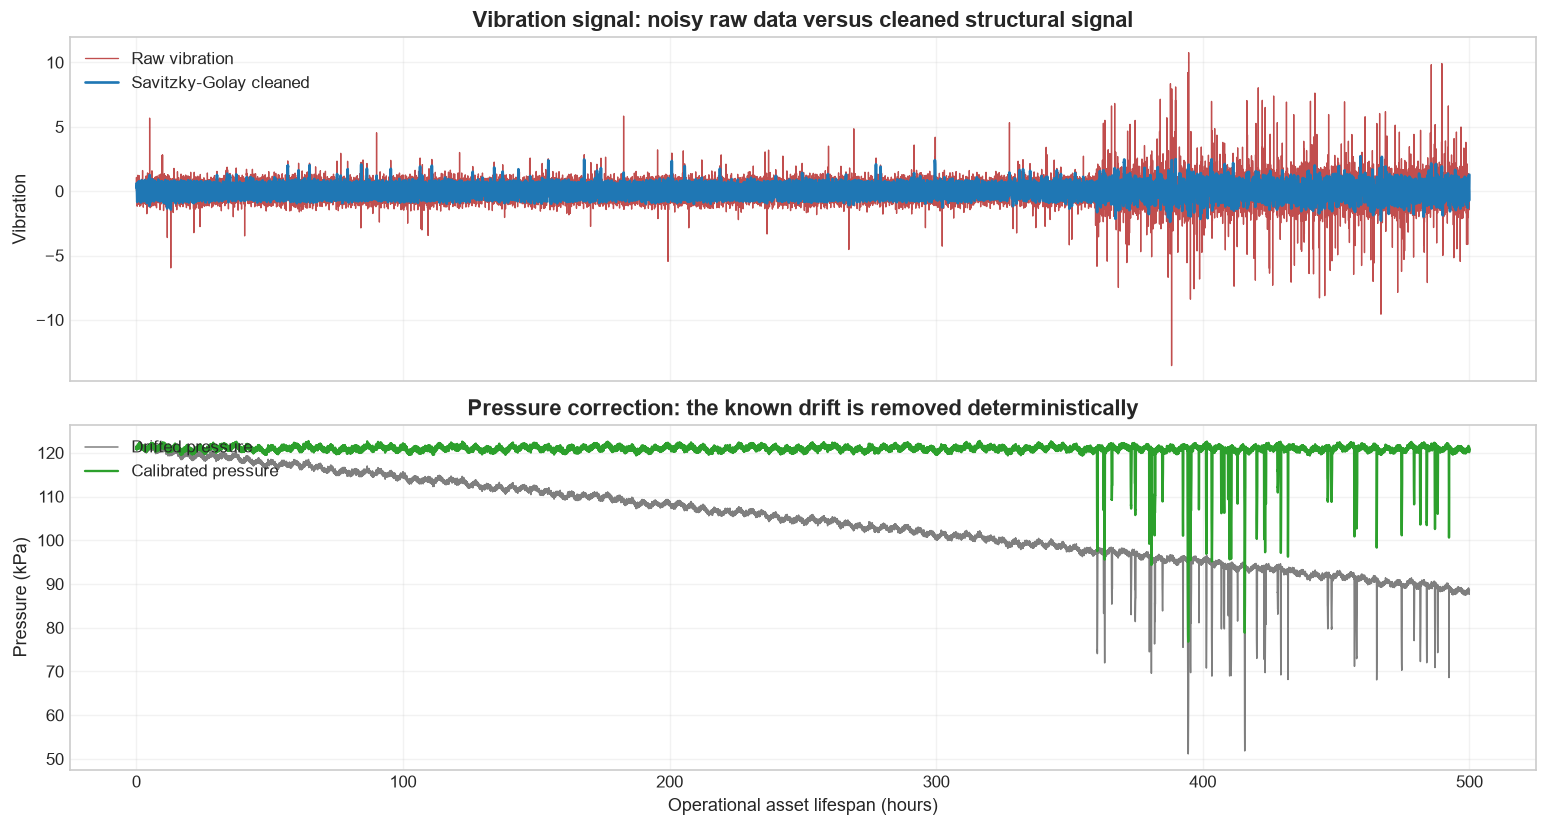

In [66]:
working_df = telemetry_df.copy()
sensor_columns = ['raw_vibration', 'drifted_pressure', 'motor_temp', 'fluid_temp']
working_df[sensor_columns] = working_df[sensor_columns].ffill().bfill()
working_df['cleaned_vibration'] = savgol_filter(working_df['raw_vibration'].to_numpy(), window_length=15, polyorder=2)
working_df['calibrated_pressure'] = working_df['drifted_pressure'].to_numpy() - (-0.065 * working_df['time_hours'].to_numpy())
working_df['vibration_rms'] = rolling_rms(working_df['cleaned_vibration'].to_numpy(), window=61)
working_df['vibration_trend'] = rolling_trend(working_df['cleaned_vibration'].to_numpy(), window=31)
working_df['pressure_reserve'] = working_df['calibrated_pressure'].to_numpy() - pd.Series(working_df['calibrated_pressure']).rolling(window=91, min_periods=1, center=True).mean().bfill().ffill().to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(working_df['time_hours'], working_df['raw_vibration'], color='#b22222', linewidth=0.8, alpha=0.8, label='Raw vibration')
axes[0].plot(working_df['time_hours'], working_df['cleaned_vibration'], color='#1f77b4', linewidth=1.6, label='Savitzky-Golay cleaned')
axes[0].set_title('Vibration signal: noisy raw data versus cleaned structural signal')
axes[0].set_ylabel('Vibration')
axes[0].legend(loc='upper left')
axes[1].plot(working_df['time_hours'], working_df['drifted_pressure'], color='#7f7f7f', linewidth=0.9, label='Drifted pressure')
axes[1].plot(working_df['time_hours'], working_df['calibrated_pressure'], color='#2ca02c', linewidth=1.4, label='Calibrated pressure')
axes[1].set_title('Pressure correction: the known drift is removed deterministically')
axes[1].set_xlabel('Operational asset lifespan (hours)')
axes[1].set_ylabel('Pressure (kPa)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

## Raw, FFT, and engineered feature views

This section makes the feature engineering tangible. The raw signal is noisy and carrier-like, the FFT reveals the hidden vibration frequencies, and the engineered features turn that messy telemetry into slow, interpretable state variables.

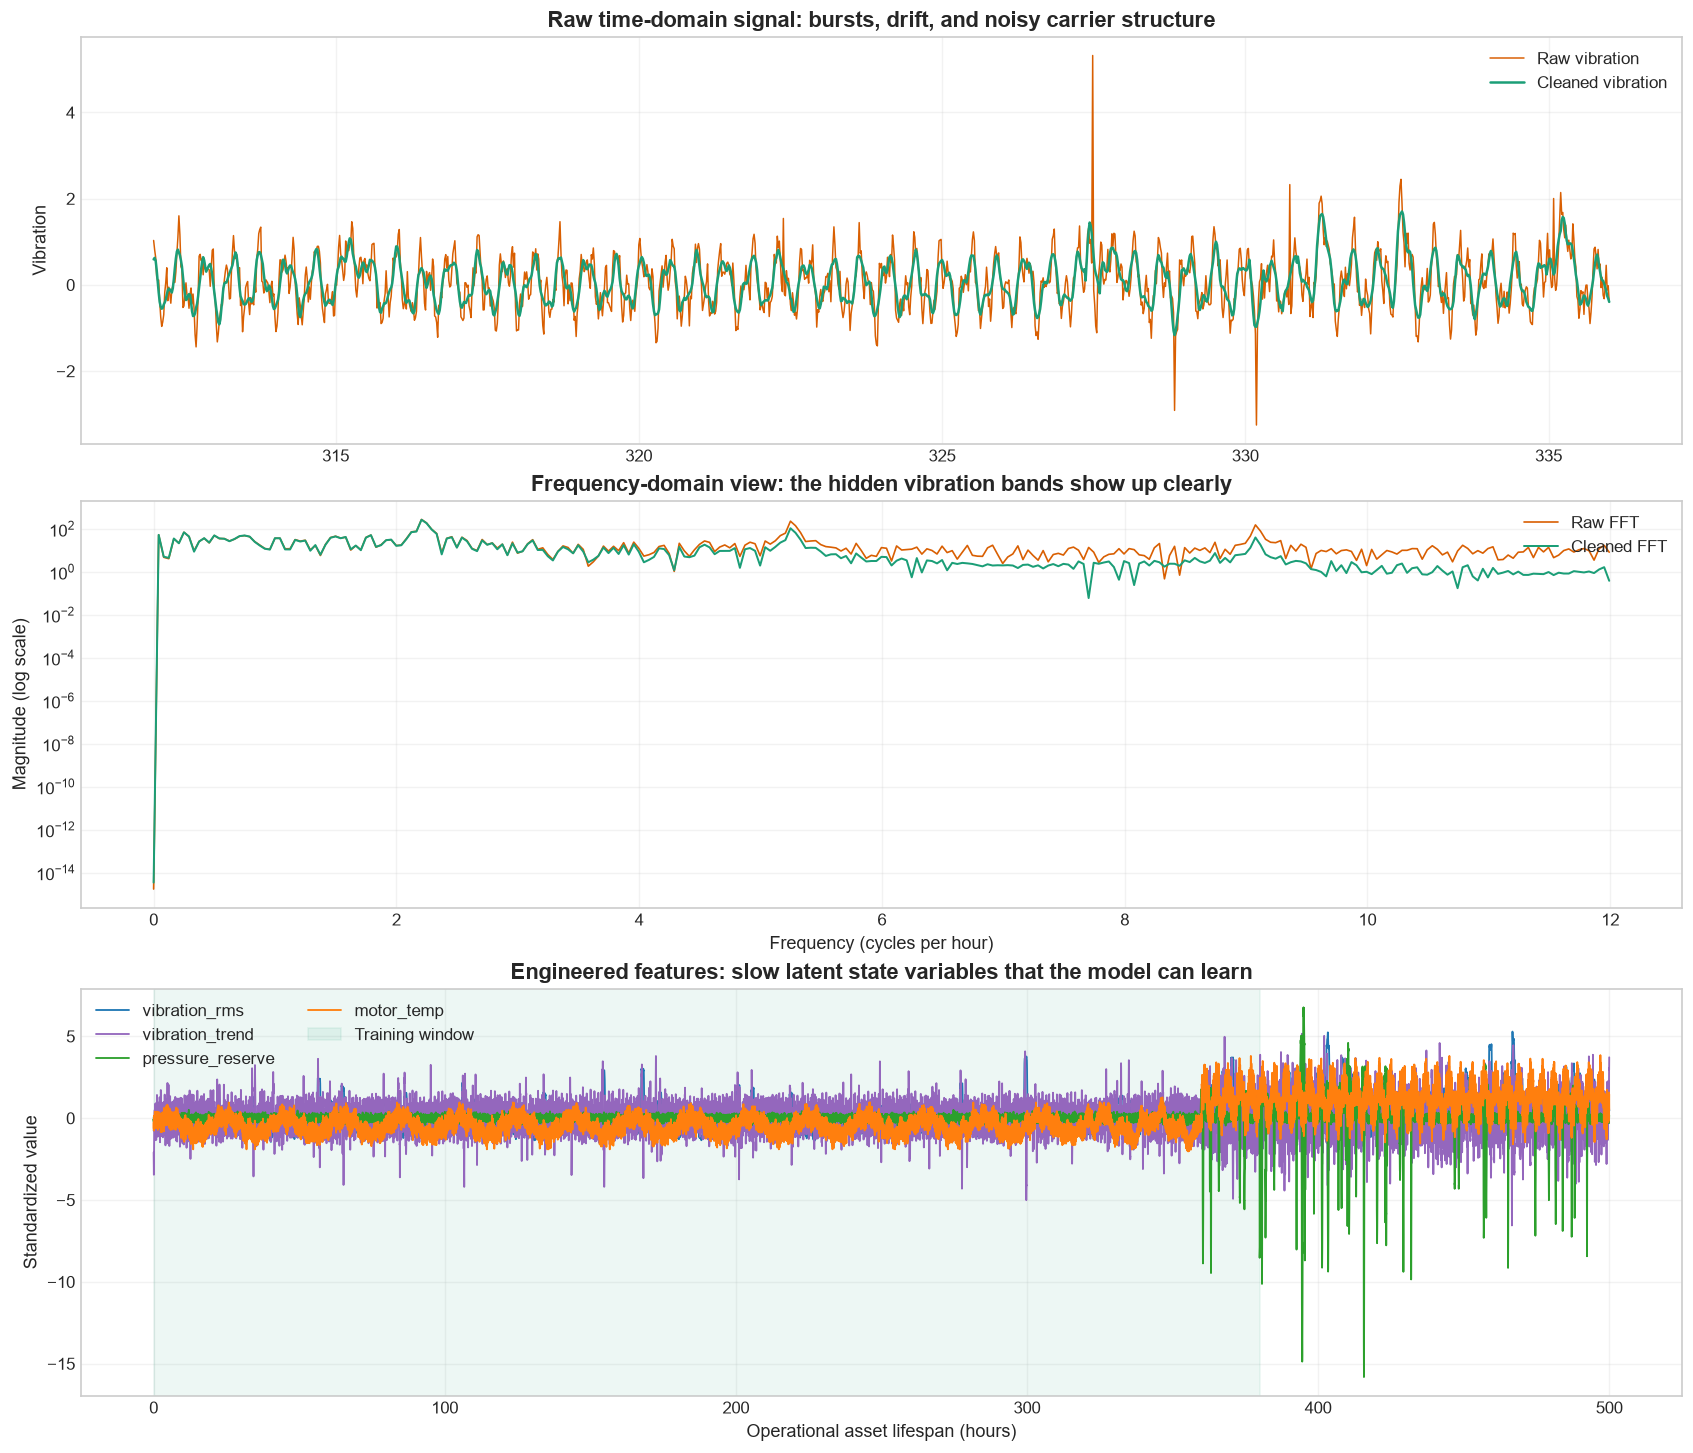

In [67]:
window_df = working_df[(working_df['time_hours'] >= 312) & (working_df['time_hours'] <= 336)].copy()
dt_hours = float(working_df['time_hours'].iloc[1] - working_df['time_hours'].iloc[0])
freq = np.fft.rfftfreq(len(window_df), d=dt_hours)
raw_fft = np.abs(np.fft.rfft(window_df['raw_vibration'].to_numpy() - window_df['raw_vibration'].mean()))
clean_fft = np.abs(np.fft.rfft(window_df['cleaned_vibration'].to_numpy() - window_df['cleaned_vibration'].mean()))
fft_mask = freq <= 12.0

feature_frame = working_df[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']].copy()
feature_z = (feature_frame - feature_frame.mean()) / feature_frame.std(ddof=0)
train_mask = working_df['suggested_split'] == 'train'
train_start = working_df.loc[train_mask, 'time_hours'].min()
train_end = working_df.loc[train_mask, 'time_hours'].max()

fig, axes = plt.subplots(3, 1, figsize=(14, 12), constrained_layout=True)

axes[0].plot(window_df['time_hours'], window_df['raw_vibration'], color='#d95f02', linewidth=0.9, label='Raw vibration')
axes[0].plot(window_df['time_hours'], window_df['cleaned_vibration'], color='#1b9e77', linewidth=1.5, label='Cleaned vibration')
axes[0].set_title('Raw time-domain signal: bursts, drift, and noisy carrier structure')
axes[0].set_ylabel('Vibration')
axes[0].legend(loc='upper right')

axes[1].semilogy(freq[fft_mask], raw_fft[fft_mask], color='#d95f02', linewidth=1.0, label='Raw FFT')
axes[1].semilogy(freq[fft_mask], clean_fft[fft_mask], color='#1b9e77', linewidth=1.2, label='Cleaned FFT')
axes[1].set_title('Frequency-domain view: the hidden vibration bands show up clearly')
axes[1].set_xlabel('Frequency (cycles per hour)')
axes[1].set_ylabel('Magnitude (log scale)')
axes[1].legend(loc='upper right')

for feature_name, color in zip(engineered_features, ['#1f77b4', '#9467bd', '#2ca02c', '#ff7f0e']):
    axes[2].plot(working_df['time_hours'], feature_z[feature_name], linewidth=1.1, color=color, label=feature_name)
axes[2].axvspan(train_start, train_end, color='#1b9e77', alpha=0.08, label='Training window')
axes[2].set_title('Engineered features: slow latent state variables that the model can learn')
axes[2].set_xlabel('Operational asset lifespan (hours)')
axes[2].set_ylabel('Standardized value')
axes[2].legend(loc='upper left', ncols=2)

plt.show()

## Raw features versus engineered features

The baseline model intentionally gets the wrong answer for the right reason: the raw fields are a noisy projection of the real failure process. The engineered features pull out the latent physical state, so the same algorithm suddenly becomes much more useful.

Naive raw-feature R^2: -0.291
Engineered physics-feature R^2: 0.711
Improvement: 1.002


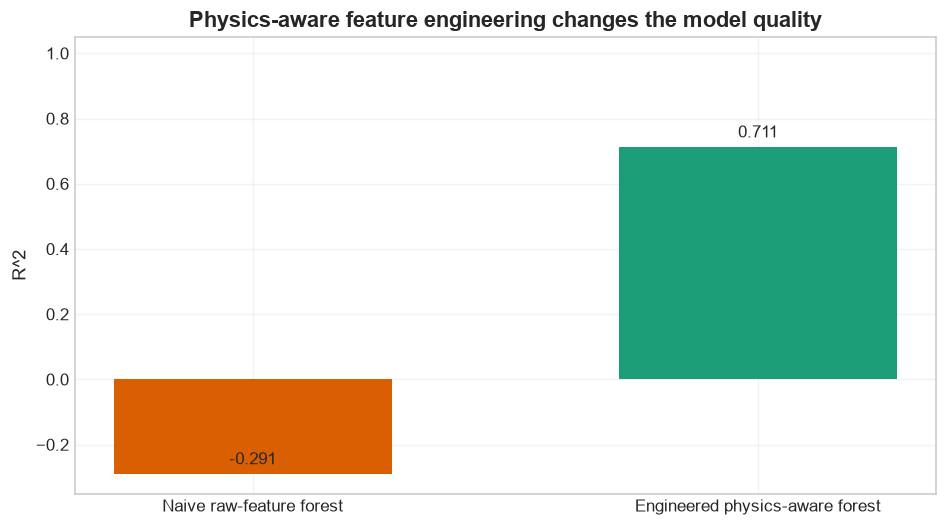

In [68]:
model_df = working_df.dropna(subset=['pump_efficiency']).copy()
train_df, test_df = train_test_split(model_df, test_size=0.3, random_state=42, shuffle=True)

baseline_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
baseline_model.fit(train_df[raw_features], train_df['pump_efficiency'])
baseline_predictions = baseline_model.predict(test_df[raw_features])
baseline_r2 = r2_score(test_df['pump_efficiency'], baseline_predictions)

engineered_model = RandomForestRegressor(n_estimators=160, random_state=42, n_jobs=-1)
engineered_model.fit(train_df[engineered_features], train_df['pump_efficiency'])
engineered_predictions = engineered_model.predict(test_df[engineered_features])
engineered_r2 = r2_score(test_df['pump_efficiency'], engineered_predictions)

print(f'Naive raw-feature R^2: {baseline_r2:.3f}')
print(f'Engineered physics-feature R^2: {engineered_r2:.3f}')
print(f'Improvement: {engineered_r2 - baseline_r2:.3f}')

comparison = pd.DataFrame({'model': ['Naive raw-feature forest', 'Engineered physics-aware forest'], 'r2': [baseline_r2, engineered_r2]})
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(comparison['model'], comparison['r2'], color=['#d95f02', '#1b9e77'], width=0.55)
ax.set_ylim(-0.35, 1.05)
ax.set_ylabel('R^2')
ax.set_title('Physics-aware feature engineering changes the model quality')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.02, f'{height:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Prediction diagnostics

The same test split can tell two different stories: one for the raw baseline and one for the physics-aware model. This plot shows how much closer the engineered model gets to the ideal diagonal, and how the residuals shrink in practice.

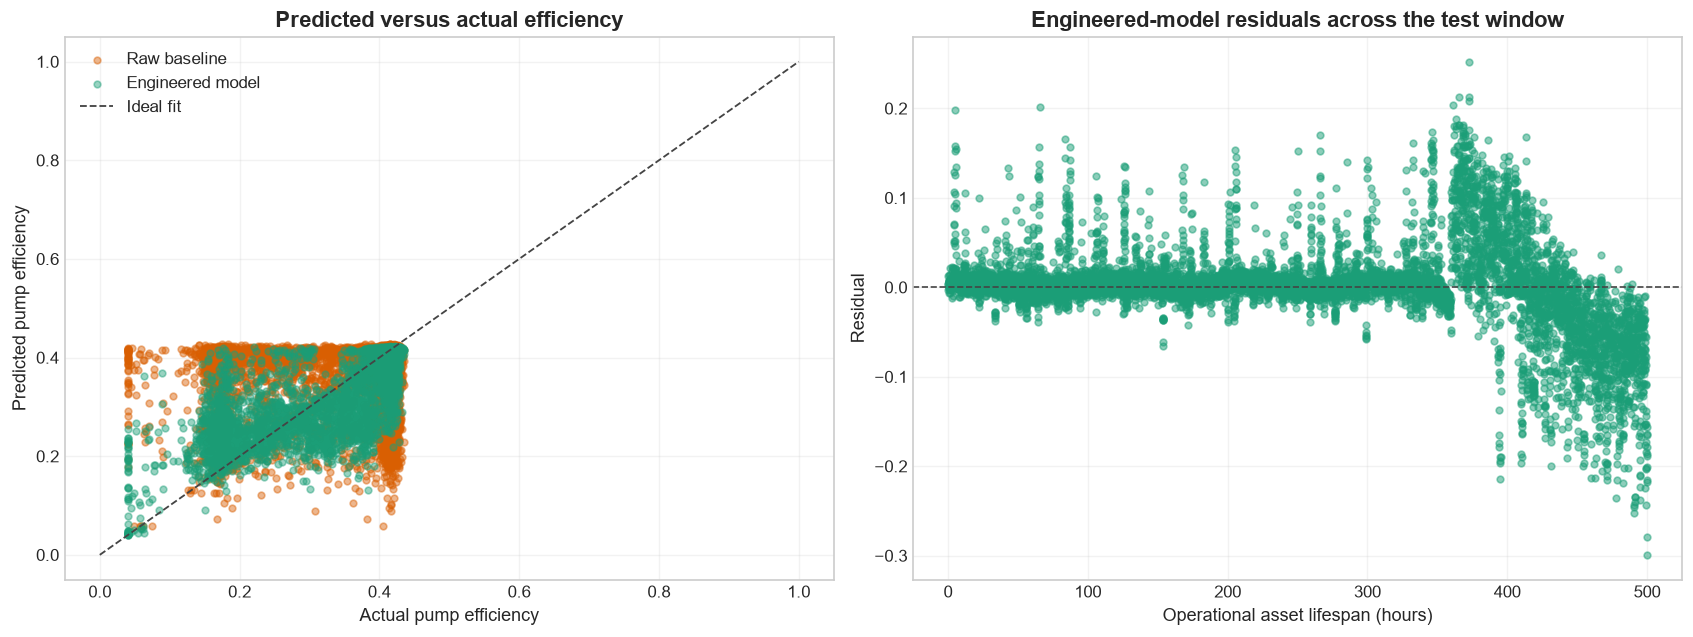

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)

axes[0].scatter(test_df['pump_efficiency'], baseline_predictions, s=16, alpha=0.45, color='#d95f02', label='Raw baseline')
axes[0].scatter(test_df['pump_efficiency'], engineered_predictions, s=16, alpha=0.45, color='#1b9e77', label='Engineered model')
axes[0].plot([0, 1], [0, 1], color='#444444', linestyle='--', linewidth=1.1, label='Ideal fit')
axes[0].set_title('Predicted versus actual efficiency')
axes[0].set_xlabel('Actual pump efficiency')
axes[0].set_ylabel('Predicted pump efficiency')
axes[0].legend(loc='upper left')

residuals = test_df['pump_efficiency'].to_numpy() - engineered_predictions
axes[1].scatter(test_df['time_hours'], residuals, s=16, alpha=0.5, color='#1b9e77')
axes[1].axhline(0.0, color='#444444', linestyle='--', linewidth=1.0)
axes[1].set_title('Engineered-model residuals across the test window')
axes[1].set_xlabel('Operational asset lifespan (hours)')
axes[1].set_ylabel('Residual')

plt.show()

## Model degradation and uncertainty

This keeps the idea from the current workshop: the model appears more confident inside the training window and becomes visibly less trustworthy once the asset leaves the operating regime it has seen before.

c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\hp\OneDrive - University of Southam

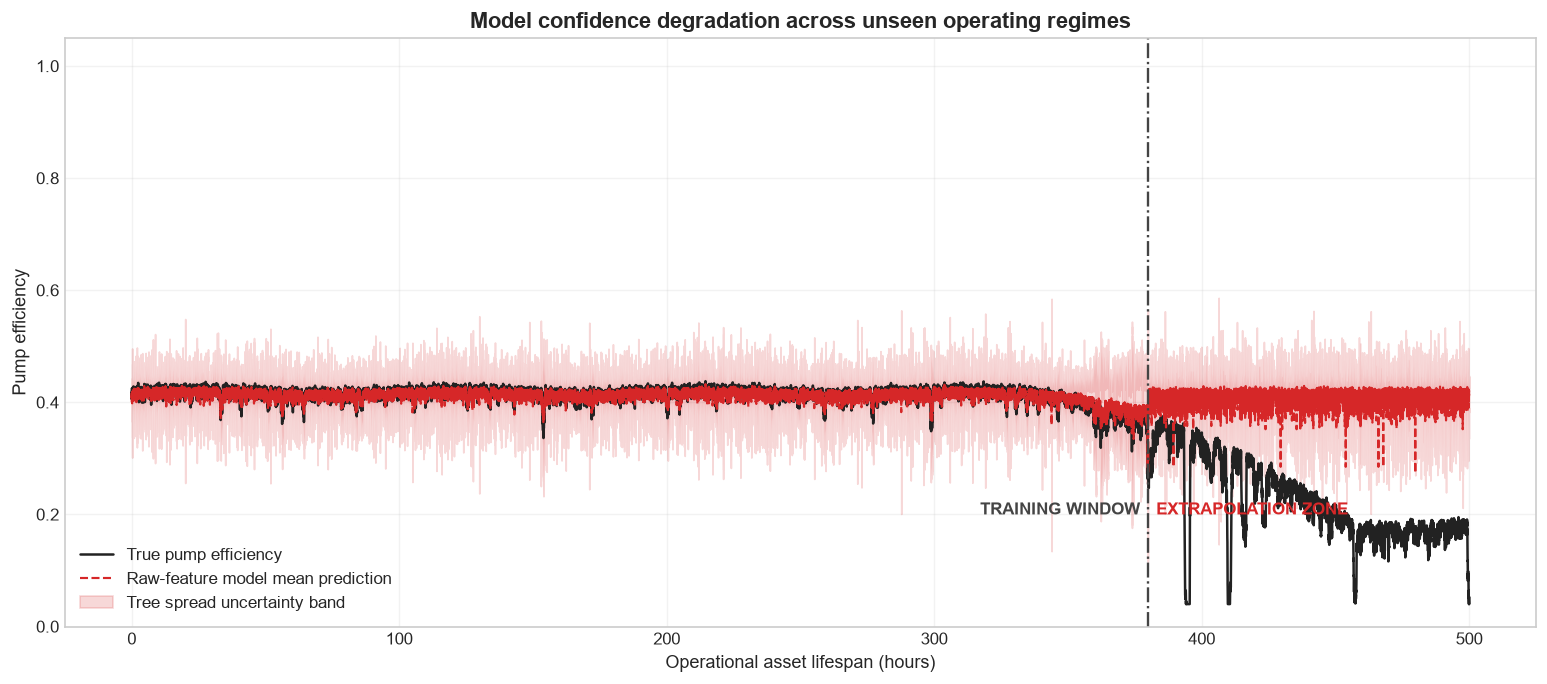

In [70]:
chrono_train = working_df[working_df['suggested_split'] == 'train'].copy()
extrapolation_model = RandomForestRegressor(n_estimators=180, random_state=42, n_jobs=-1)
extrapolation_model.fit(chrono_train[raw_features], chrono_train['pump_efficiency'])

all_tree_runs = np.stack([tree.predict(working_df[raw_features]) for tree in extrapolation_model.estimators_], axis=0)
mean_pred = all_tree_runs.mean(axis=0)
std_pred = all_tree_runs.std(axis=0)

fig, ax = plt.subplots(figsize=(13, 5.8))
ax.plot(working_df['time_hours'], working_df['pump_efficiency'], color='#222222', linewidth=1.5, label='True pump efficiency')
ax.plot(working_df['time_hours'], mean_pred, color='#d62728', linestyle='--', linewidth=1.3, label='Raw-feature model mean prediction')
ax.fill_between(working_df['time_hours'], mean_pred - 3.5 * std_pred, mean_pred + 3.5 * std_pred, color='#d62728', alpha=0.18, label='Tree spread uncertainty band')
cutoff_hour = chrono_train['time_hours'].max()
ax.axvline(x=cutoff_hour, color='#444444', linestyle='-.', linewidth=1.4)
ax.text(cutoff_hour - 3, 0.2, 'TRAINING WINDOW', ha='right', color='#444444', weight='bold')
ax.text(cutoff_hour + 3, 0.2, 'EXTRAPOLATION ZONE', ha='left', color='#d62728', weight='bold')
ax.set_ylim(0.0, 1.05)
ax.set_xlabel('Operational asset lifespan (hours)')
ax.set_ylabel('Pump efficiency')
ax.set_title('Model confidence degradation across unseen operating regimes')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## Gaussian-process uncertainty in an extreme slice

The uncertainty story becomes even clearer when we deliberately push the pump into a thermal runaway scenario. The mean prediction is not enough on its own; the spread matters.

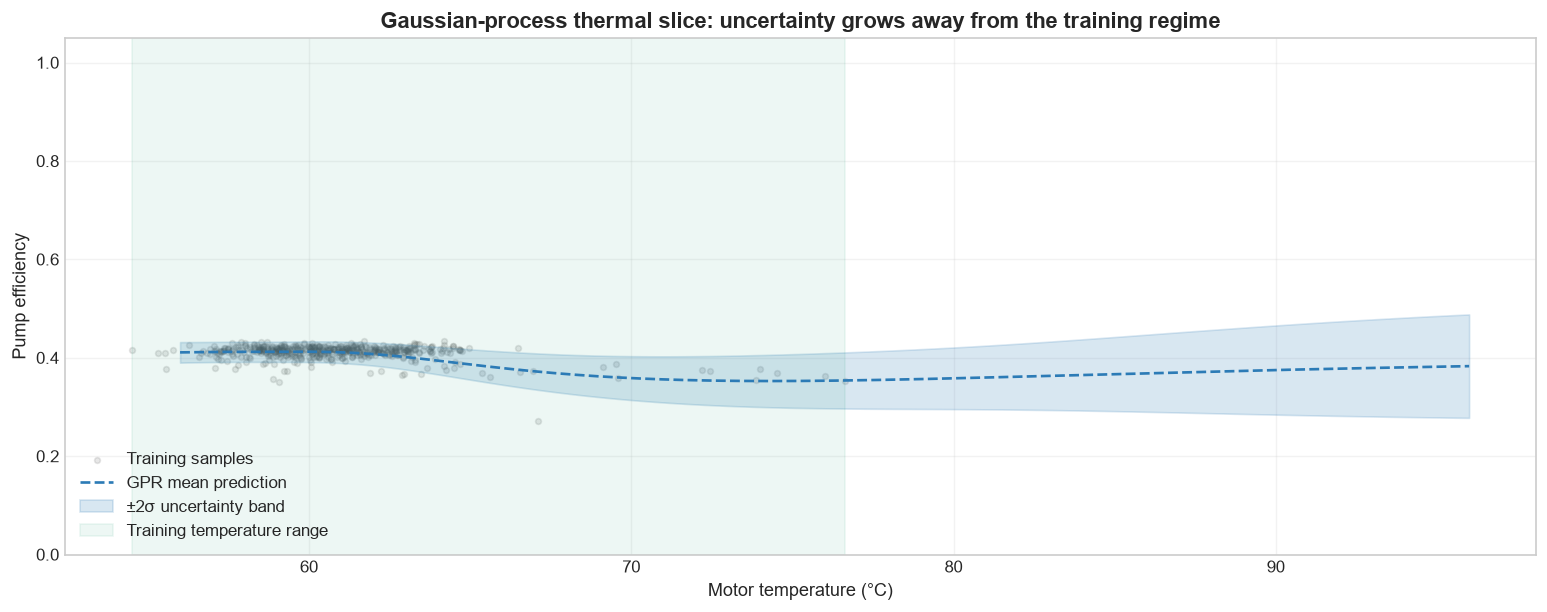

In [71]:
gp_train = chrono_train[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp', 'pump_efficiency']].sample(n=min(500, len(chrono_train)), random_state=42).sort_values('motor_temp').copy()
gpr_features_train = gp_train[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']].copy()
gpr_scaler = StandardScaler()
gpr_train_scaled = gpr_scaler.fit_transform(gpr_features_train)

kernel = ConstantKernel(1.0, (0.01, 100.0)) * Matern(length_scale=np.ones(gpr_features_train.shape[1]), length_scale_bounds=(0.01, 50.0), nu=1.5) + WhiteKernel(noise_level=0.01, noise_level_bounds=(1e-6, 0.5))
gpr = GaussianProcessRegressor(kernel=kernel, alpha=0.0, normalize_y=True, n_restarts_optimizer=2, random_state=42)
gpr.fit(gpr_train_scaled, gp_train['pump_efficiency'])

slice_anchor = gpr_features_train.median()
thermal_axis = np.linspace(56.0, 96.0, 180)
gpr_slice = pd.DataFrame({
    'vibration_rms': np.full(thermal_axis.size, slice_anchor['vibration_rms']),
    'vibration_trend': np.linspace(slice_anchor['vibration_trend'], slice_anchor['vibration_trend'] + 0.03, thermal_axis.size),
    'pressure_reserve': np.linspace(slice_anchor['pressure_reserve'], slice_anchor['pressure_reserve'] - 7.5, thermal_axis.size),
    'motor_temp': thermal_axis,
})
gpr_mean, gpr_std = gpr.predict(gpr_scaler.transform(gpr_slice), return_std=True)
training_temp_range = (gp_train['motor_temp'].min(), gp_train['motor_temp'].max())

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.scatter(gp_train['motor_temp'], gp_train['pump_efficiency'], s=12, alpha=0.14, color='#555555', label='Training samples')
ax.plot(thermal_axis, gpr_mean, color='#2c7bb6', linewidth=1.6, linestyle='--', label='GPR mean prediction')
ax.fill_between(thermal_axis, np.clip(gpr_mean - 2 * gpr_std, 0, 1), np.clip(gpr_mean + 2 * gpr_std, 0, 1), color='#2c7bb6', alpha=0.18, label='±2σ uncertainty band')
ax.axvspan(training_temp_range[0], training_temp_range[1], color='#1b9e77', alpha=0.08, label='Training temperature range')
ax.set_ylim(0.0, 1.05)
ax.set_xlabel('Motor temperature (°C)')
ax.set_ylabel('Pump efficiency')
ax.set_title('Gaussian-process thermal slice: uncertainty grows away from the training regime')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## Forensic audit with SHAP

SHAP (SHapley Additive exPlanations) utilizes game theory to fairly allocate feature attribution metrics to individual sensor channels.


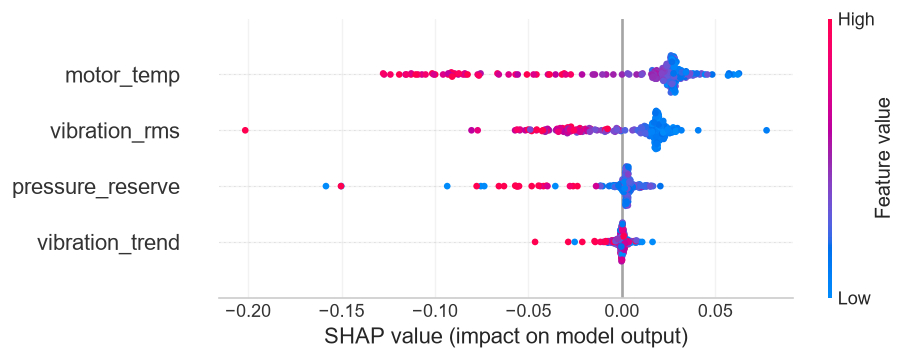

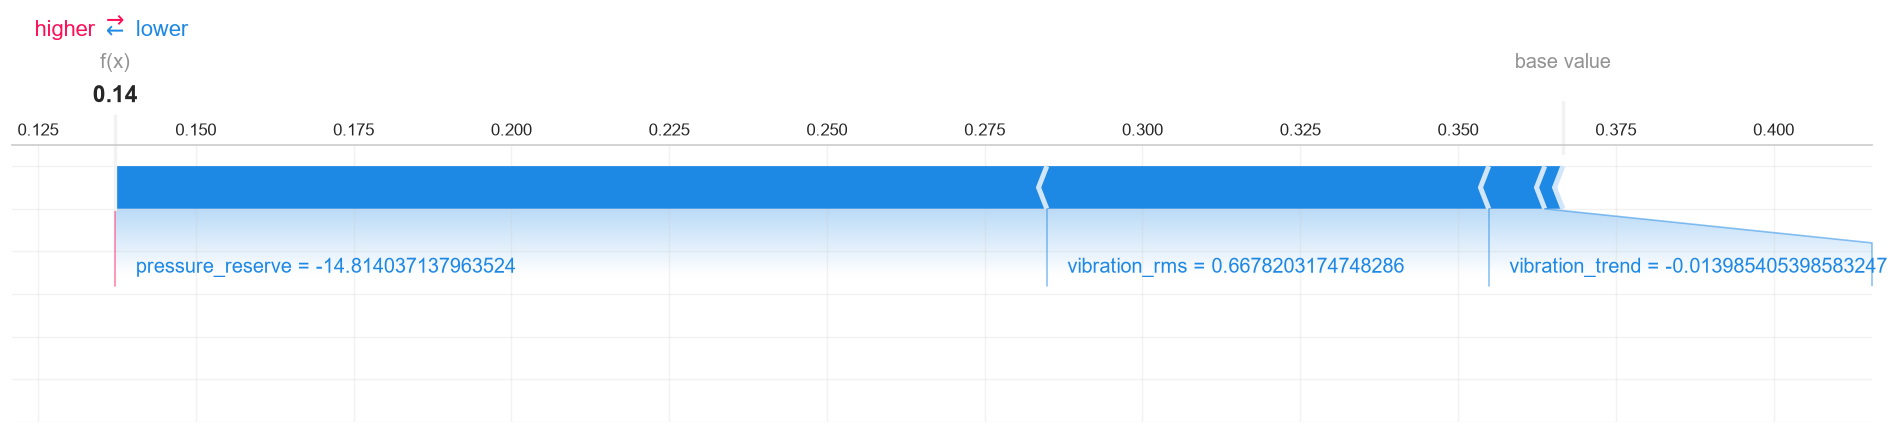

In [72]:
shap_sample = test_df[engineered_features].sample(n=min(240, len(test_df)), random_state=42)
shap_explainer = shap.TreeExplainer(engineered_model)
shap_values = shap_explainer.shap_values(shap_sample)

shap.summary_plot(shap_values, shap_sample, show=True)

anomalous_row = test_df.sort_values('pump_efficiency').head(1)[engineered_features]
shap_force = shap_explainer.shap_values(anomalous_row)
shap.force_plot(shap_explainer.expected_value, shap_force[0], anomalous_row.iloc[0], matplotlib=True, show=True)

## Wrap-up

The presentation story is now consistent from end to end: the emulator creates the failure process, the raw features look poor, the engineered features recover the physics, and the uncertainty/degradation plots make the regime shift visually obvious.